# BottleneckIQ — ML Production Pipeline
This notebook trains a Random Forest model using combined MIMIC-IV-ED chunks (test_chunk_1/2/10) and aligns to production feature rules.

Same end-to-end pipeline as simulation, but built on the larger (sparse) dataset.

In [26]:
# 1. Imports
import os
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import MultiLabelBinarizer
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set(style='whitegrid')
DATA_DIR = Path('.')
CHUNKS = [DATA_DIR / 'data_MIMIC.csv']
print('chunk files', CHUNKS)

chunk files [WindowsPath('data_MIMIC.csv')]


In [27]:
# 2. Load & combine
dfs = []
for f in CHUNKS:
    if f.exists():
        dfs.append(pd.read_csv(f))
    else:
        print('missing chunk', f)

df = pd.concat(dfs, ignore_index=True)
print('shape combined', df.shape)
print('columns', df.columns.tolist())

shape combined (494605, 31)
columns ['stay_id', 'subject_id', 'hadm_id', 'timestamps', 'activity', 'gender', 'race', 'arrival_transport', 'disposition', 'seq_num', 'icd_code', 'icd_version', 'icd_title', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint', 'rhythm', 'name', 'gsn', 'ndc', 'etc_rn', 'etccode', 'etcdescription', 'med_rn', 'gsn_rn']


In [28]:
# 3. Feature engineering (IQ logic)
# chiefcomplaint tokenization (memory-efficient)
if 'chiefcomplaint' in df.columns:
    complaint_lists = (
        df['chiefcomplaint'].fillna('').astype(str)
          .str.split(',')
          .apply(lambda tokens: [t.strip().lower() for t in tokens if t.strip()])
    )
    from collections import Counter
    all_tokens = Counter(tok for row in complaint_lists for tok in row)
    top20 = [tok for tok, _ in all_tokens.most_common(20)]
    for tok in top20:
        df[f'complaint_{tok}'] = complaint_lists.apply(lambda row, token=tok: int(token in row))
    mlb = None
else:
    mlb = None

# temporal features
timestamp_col = 'timestamp' if 'timestamp' in df.columns else 'timestamps' if 'timestamps' in df.columns else None
if not timestamp_col:
    raise ValueError('timestamp required')

df[timestamp_col] = pd.to_datetime(df[timestamp_col], errors='coerce')
# keep standardized column for downstream
if timestamp_col != 'timestamp':
    df['timestamp'] = df[timestamp_col]

df['hour_of_day'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)

# high intensity
df['high_intensity'] = 0
acuity_col = 'Acuity' if 'Acuity' in df.columns else 'acuity' if 'acuity' in df.columns else None
arrival_col = 'Arrival' if 'Arrival' in df.columns else 'arrival_transport' if 'arrival_transport' in df.columns else None
if acuity_col and arrival_col:
    df['high_intensity'] = ((df[acuity_col].astype(float) <= 2) & df[arrival_col].astype(str).str.lower().str.contains('ambulance', na=False)).astype(int)

# arrival dummies
if arrival_col:
    df = pd.concat([df, pd.get_dummies(df[arrival_col].astype(str), prefix='Arrival', dummy_na=False)], axis=1)

print('features built, sample:')
print(df[['hour_of_day','day_of_week','is_weekend','high_intensity']].head())

features built, sample:
   hour_of_day  day_of_week  is_weekend  high_intensity
0           17            1           0               0
1           17            1           0               0
2           17            1           0               0
3           18            1           0               0
4           18            1           0               0


In [29]:
# 4. Throughput and bottleneck labeling (aligned to backend event-level logic)

def compute_stay_timings_from_events(df_events):
    df_events = df_events[['stay_id', 'timestamps', 'activity']].copy()
    df_events['stay_id'] = pd.to_numeric(df_events['stay_id'], errors='coerce')
    df_events['activity'] = (
        df_events['activity'].astype(str)
            .str.strip()
            .str.lower()
    )
    mapping = {
        'enter the ed': 'entry',
        'triage in the ed': 'triage',
        'vital sign check': 'vital',
        'medicine reconciliation': 'medrecon',
        'medicine dispensations': 'dispen',
        'discharge from the ed': 'discharge'
    }
    df_events['activity'] = df_events['activity'].replace(mapping)

    df_events['timestamps'] = pd.to_datetime(df_events['timestamps'], errors='coerce')
    df_events = df_events.dropna(subset=['stay_id', 'timestamps', 'activity'])
    df_events = df_events.sort_values(['stay_id', 'timestamps'])

    stay_records = []
    expected_stages = ['triage', 'vital', 'medrecon', 'dispen']

    for stay_id, group in df_events.groupby('stay_id'):
        rows = group.to_dict('records')
        if len(rows) < 2:
            continue

        total_los = (rows[-1]['timestamps'] - rows[0]['timestamps']).total_seconds() / 60.0
        metrics = {
            'stay_id': stay_id,
            'total_ed_stay_time': total_los,
            'time_to_triage': None,
            'time_to_vital': None,
            'time_to_medrecon': None,
            'time_to_dispen': None,
            'time_to_discharge': None,
            'skipped_stages': []
        }

        for i in range(1, len(rows)):
            prev = rows[i - 1]
            curr = rows[i]
            delta_min = (curr['timestamps'] - prev['timestamps']).total_seconds() / 60.0
            stage_key = f"time_to_{curr['activity']}"
            if stage_key in metrics:
                metrics[stage_key] = delta_min

        for s in expected_stages:
            if metrics[f'time_to_{s}'] is None:
                metrics['skipped_stages'].append(s.capitalize())

        metrics['skipped_stages'] = ', '.join(metrics['skipped_stages'])
        stay_records.append(metrics)

    return pd.DataFrame(stay_records)

if {'stay_id', 'timestamps', 'activity'}.issubset(df.columns):
    timing_df = compute_stay_timings_from_events(df)
    df = df.merge(timing_df, on='stay_id', how='left')
else:
    # existing time_to_* columns are used directly
    pass

stages = ['vital', 'medrecon', 'dispen', 'discharge']
for stage in stages:
    col = f'time_to_{stage}'
    if col not in df.columns:
        df[col] = np.nan
    df[f'skipped_{stage}'] = df[col].isna().astype(int)

for stage in stages:
    col = f'time_to_{stage}'
    p90 = df[col].dropna().quantile(0.90)
    df[f'is_bottleneck_{stage}'] = ((df[col] > p90) & df[col].notna()).astype(int)

# overall label
df['is_bottleneck'] = df[[f'is_bottleneck_{s}' for s in stages]].max(axis=1).astype(int)
print('bottleneck balance:', df['is_bottleneck'].value_counts(dropna=False).to_dict())

bottleneck balance: {0: 341111, 1: 153494}


In [33]:
# 5. Model training
if 'stay_id' not in df.columns:
    raise ValueError('stay_id required for grouping')

feature_cols = [c for c in df.columns if c.startswith('complaint_') or c.startswith('Arrival_') or c in ['hour_of_day','day_of_week','is_weekend','high_intensity']]
feature_cols += [f'skipped_{s}' for s in stages]
feature_cols = [c for c in feature_cols if c in df.columns]

X = df[feature_cols].fillna(0)
y = df['is_bottleneck']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X,y,groups=df['stay_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_train, y_train)

print('train', rf.score(X_train, y_train), 'test', rf.score(X_test, y_test))

train 0.5206210050276648 test 0.5087099549572347


              precision    recall  f1-score   support

           0       0.73      0.46      0.57     68211
           1       0.34      0.61      0.43     30584

    accuracy                           0.51     98795
   macro avg       0.53      0.54      0.50     98795
weighted avg       0.60      0.51      0.53     98795



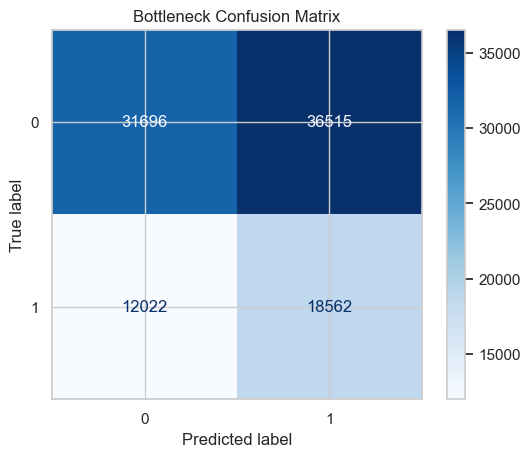

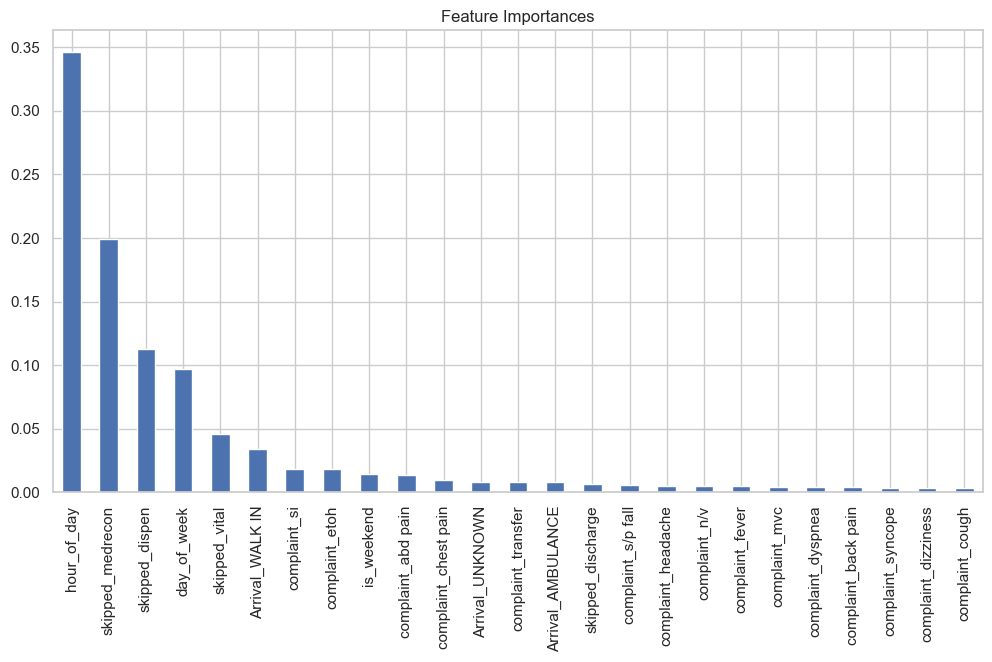

In [34]:
# 6. Evaluation
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=[0,1]).plot(cmap='Blues')
plt.title('Bottleneck Confusion Matrix')
plt.show()

fi = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(12,6))
fi.head(25).plot(kind='bar')
plt.title('Feature Importances')
plt.show()

In [35]:
# 7. Save artifacts
artifact_dir = DATA_DIR / 'production_model_artifacts'
artifact_dir.mkdir(exist_ok=True)
joblib.dump(rf, artifact_dir / 'rf_bottleneck_production.joblib')
if mlb is not None:
    joblib.dump(mlb, artifact_dir / 'chiefcomplaint_mlb_production.joblib')
print('saved to', artifact_dir)

saved to production_model_artifacts
